# METALYX — ShuffleNetV2 + SimCLR Encoder Experiment

**Purpose:** Train a ShuffleNetV2 encoder with the project's existing SimCLR approach, extract image features, and evaluate a Logistic Regression downstream classifier.

**Important for a fair comparison**
- This notebook creates a fixed, stratified train/validation/test split from the 1,440 images in `NEU-DET/train/images`.
- SimCLR pretraining uses **training images only**. Validation and test images are not used to train the encoder.
- The encoder is trained from scratch (`weights=None`) to match the current ResNet18 SimCLR setup.
- To compare fairly, rerun the same protocol with ResNet18 using the same split seed, training settings, and evaluation cells. The historical 86.11%, 92.50%, and ~96% results may have used different protocols, so do not treat them as a direct apples-to-apples comparison until verified.



## 1. Mount Google Drive and import libraries

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import random
import json
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision.models as models
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

PyTorch: 2.11.0+cu130
CUDA available: True
Using device: cuda


## 2. Set paths and reproducibility settings

In [ ]:
SEED = 42
# Use "shufflenet_v2_x1_0" for the requested experiment.
# Change to "resnet18" and rerun all cells for the baseline comparison.
ENCODER_NAME = "shufflenet_v2_x1_0"
DATASET_PATH = "/content/drive/MyDrive/NEU-DET/train/images"
OUTPUT_DIR = "/content/drive/MyDrive/METALYX/shufflenet_experiment"
MODEL_DIR = os.path.join(OUTPUT_DIR, "models")
RESULTS_DIR = os.path.join(OUTPUT_DIR, "results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

class_names = [
    "crazing", "inclusion", "patches",
    "pitted_surface", "rolled-in_scale", "scratches"
]
class_to_idx = {name: idx for idx, name in enumerate(class_names)}
idx_to_class = {idx: name for name, idx in class_to_idx.items()}

print("Dataset path exists:", os.path.isdir(DATASET_PATH))
print("Output directory:", OUTPUT_DIR)

Dataset path exists: True
Output directory: /content/drive/MyDrive/METALYX/shufflenet_experiment


## 3. Read image paths and labels

In [ ]:
image_extensions = (".jpg", ".jpeg", ".png", ".bmp")
image_paths, labels = [], []

for class_name in class_names:
    class_dir = os.path.join(DATASET_PATH, class_name)
    if not os.path.isdir(class_dir):
        raise FileNotFoundError(f"Expected class folder not found: {class_dir}")

    for filename in sorted(os.listdir(class_dir)):
        if filename.lower().endswith(image_extensions):
            image_paths.append(os.path.join(class_dir, filename))
            labels.append(class_to_idx[class_name])

image_paths = np.asarray(image_paths)
labels = np.asarray(labels, dtype=np.int64)

print("Total images:", len(image_paths))
print("Total labels:", len(labels))
print(pd.Series([idx_to_class[int(y)] for y in labels]).value_counts().reindex(class_names))
assert len(image_paths) == len(labels) and len(image_paths) > 0

Total images: 1440
Total labels: 1440
crazing            240
inclusion          240
patches            240
pitted_surface     240
rolled-in_scale    240
scratches          240
Name: count, dtype: int64


## 4. Create one fixed, stratified split

The split is created **before SimCLR training** so validation and test images remain unseen during encoder training. The split is 70% train, 15% validation, and 15% test.

Save these image paths and use the same split when you run the ResNet18 baseline.

In [ ]:
train_paths, temp_paths, y_train, y_temp = train_test_split(
    image_paths, labels,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

val_paths, test_paths, y_val, y_test = train_test_split(
    temp_paths, y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print(f"Train: {len(train_paths)} images")
print(f"Validation: {len(val_paths)} images")
print(f"Test: {len(test_paths)} images")

split_manifest = {
    "seed": SEED,
    "train_paths": train_paths.tolist(),
    "val_paths": val_paths.tolist(),
    "test_paths": test_paths.tolist()
}
manifest_path = os.path.join(OUTPUT_DIR, "split_manifest_seed42.json")
with open(manifest_path, "w") as f:
    json.dump(split_manifest, f, indent=2)
print("Saved split manifest:", manifest_path)

Train: 1008 images
Validation: 216 images
Test: 216 images
Saved split manifest: /content/drive/MyDrive/METALYX/shufflenet_experiment/split_manifest_seed42.json


## 5. Define the SimCLR augmentations and dataset

In [ ]:
simclr_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomResizedCrop(size=224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(
        brightness=0.4, contrast=0.4, saturation=0.4, hue=0.1
    ),
    transforms.RandomApply(
        [transforms.GaussianBlur(kernel_size=23)], p=0.5
    ),
    transforms.ToTensor()
])

feature_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

class SimCLRDataset(Dataset):
    def __init__(self, paths, transform):
        self.paths = list(paths)
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        image_path = self.paths[index]
        image = cv2.imread(image_path)
        if image is None:
            raise RuntimeError(f"Could not read image: {image_path}")
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        view1 = self.transform(image)
        view2 = self.transform(image)
        return view1, view2

simclr_dataset = SimCLRDataset(train_paths, simclr_transform)
BATCH_SIZE = 32
simclr_loader = DataLoader(
    simclr_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2 if os.name != "nt" else 0,
    pin_memory=torch.cuda.is_available(),
    drop_last=True
)

view1, view2 = next(iter(simclr_loader))
print("Training images for SimCLR:", len(simclr_dataset))
print("View 1 batch:", tuple(view1.shape))
print("View 2 batch:", tuple(view2.shape))

Training images for SimCLR: 1008
View 1 batch: (32, 3, 224, 224)
View 2 batch: (32, 3, 224, 224)


## 6. Define ShuffleNetV2 + projection head

In [ ]:
class SimCLR(nn.Module):
    def __init__(self, projection_dim=128):
        super().__init__()

        # Choose the encoder here. Both are trained from scratch for a fair comparison.
        if ENCODER_NAME == "shufflenet_v2_x1_0":
            self.encoder = models.shufflenet_v2_x1_0(weights=None)
        elif ENCODER_NAME == "resnet18":
            self.encoder = models.resnet18(weights=None)
        else:
            raise ValueError(f"Unsupported encoder: {ENCODER_NAME}")

        # Remove the ImageNet classification layer and keep its input features.
        num_features = self.encoder.fc.in_features
        self.encoder.fc = nn.Identity()

        self.projector = nn.Sequential(
            nn.Linear(num_features, 512),
            nn.ReLU(inplace=True),
            nn.Linear(512, projection_dim)
        )

        self.feature_dim = num_features
        self.projection_dim = projection_dim

    def forward(self, x):
        features = self.encoder(x)
        projections = self.projector(features)
        return features, projections

PROJECTION_DIM = 128
model = SimCLR(projection_dim=PROJECTION_DIM).to(device)

print("Encoder:", ENCODER_NAME)
print("Feature dimension:", model.feature_dim)
print("Projection dimension:", model.projection_dim)

# Shape check before training
with torch.no_grad():
    dummy = torch.randn(2, 3, 224, 224, device=device)
    dummy_features, dummy_projections = model(dummy)
print("Feature output shape:", tuple(dummy_features.shape))
print("Projection output shape:", tuple(dummy_projections.shape))
assert dummy_features.shape[1] == model.feature_dim, "Unexpected feature dimension"

Encoder: shufflenet_v2_x1_0
Feature dimension: 1024
Projection dimension: 128
Feature output shape: (2, 1024)
Projection output shape: (2, 128)


## 7. Define NT-Xent contrastive loss

In [ ]:
class NTXentLoss(nn.Module):
    def __init__(self, temperature=0.5):
        super().__init__()
        self.temperature = temperature

    def forward(self, z1, z2):
        batch_size = z1.size(0)
        z1 = F.normalize(z1, dim=1)
        z2 = F.normalize(z2, dim=1)

        representations = torch.cat([z1, z2], dim=0)
        logits = representations @ representations.T
        logits = logits / self.temperature

        diagonal_mask = torch.eye(
            2 * batch_size, dtype=torch.bool, device=logits.device
        )
        logits = logits.masked_fill(diagonal_mask, -1e9)

        targets = torch.arange(2 * batch_size, device=logits.device)
        targets = (targets + batch_size) % (2 * batch_size)

        return F.cross_entropy(logits, targets)

TEMPERATURE = 0.5
criterion = NTXentLoss(temperature=TEMPERATURE)

## 8. Configure training

In [ ]:
LEARNING_RATE = 0.001
NUM_EPOCHS = 50

optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
loss_history = []

print("Epochs:", NUM_EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Temperature:", TEMPERATURE)
print("Batch size:", BATCH_SIZE)

Epochs: 50
Learning rate: 0.001
Temperature: 0.5
Batch size: 32


## 9. Train ShuffleNetV2 with SimCLR

This cell trains the encoder and projection head. It can take time. Use a GPU runtime if available.

In [ ]:
start_time = time.time()

# Create checkpoint directory
os.makedirs(MODEL_DIR, exist_ok=True)

checkpoint_path = os.path.join(
    MODEL_DIR, f"simclr_{ENCODER_NAME}_latest.pth"
)

for epoch in range(NUM_EPOCHS):
    model.train()
    running_loss = 0.0
    batches_seen = 0

    for view1, view2 in simclr_loader:
        view1 = view1.to(device, non_blocking=True)
        view2 = view2.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        _, z1 = model(view1)
        _, z2 = model(view2)

        loss = criterion(z1, z2)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        batches_seen += 1

    epoch_loss = running_loss / max(batches_seen, 1)
    loss_history.append(epoch_loss)

    print(
        f"Epoch [{epoch + 1:02d}/{NUM_EPOCHS}] "
        f"- NT-Xent loss: {epoch_loss:.4f}"
    )

    # Save checkpoint after every epoch
    torch.save({
        "epoch": epoch + 1,
        "encoder_name": ENCODER_NAME,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "loss_history": loss_history,
        "feature_dim": model.feature_dim,
        "temperature": TEMPERATURE,
    }, checkpoint_path)

    print(f"Checkpoint saved: {checkpoint_path}")

training_seconds = time.time() - start_time

print(f"Training time: {training_seconds / 60:.2f} minutes")
print("Final checkpoint exists:", os.path.exists(checkpoint_path))

Epoch [01/50] - NT-Xent loss: 3.8847
Checkpoint saved: /content/drive/MyDrive/METALYX/shufflenet_experiment/models/simclr_shufflenet_v2_x1_0_latest.pth
Epoch [02/50] - NT-Xent loss: 3.7913
Checkpoint saved: /content/drive/MyDrive/METALYX/shufflenet_experiment/models/simclr_shufflenet_v2_x1_0_latest.pth
Epoch [03/50] - NT-Xent loss: 3.7336
Checkpoint saved: /content/drive/MyDrive/METALYX/shufflenet_experiment/models/simclr_shufflenet_v2_x1_0_latest.pth
Epoch [04/50] - NT-Xent loss: 3.6695
Checkpoint saved: /content/drive/MyDrive/METALYX/shufflenet_experiment/models/simclr_shufflenet_v2_x1_0_latest.pth
Epoch [05/50] - NT-Xent loss: 3.5698
Checkpoint saved: /content/drive/MyDrive/METALYX/shufflenet_experiment/models/simclr_shufflenet_v2_x1_0_latest.pth
Epoch [06/50] - NT-Xent loss: 3.4438
Checkpoint saved: /content/drive/MyDrive/METALYX/shufflenet_experiment/models/simclr_shufflenet_v2_x1_0_latest.pth
Epoch [07/50] - NT-Xent loss: 3.3587
Checkpoint saved: /content/drive/MyDrive/METALYX/sh

## 10. Plot the training loss

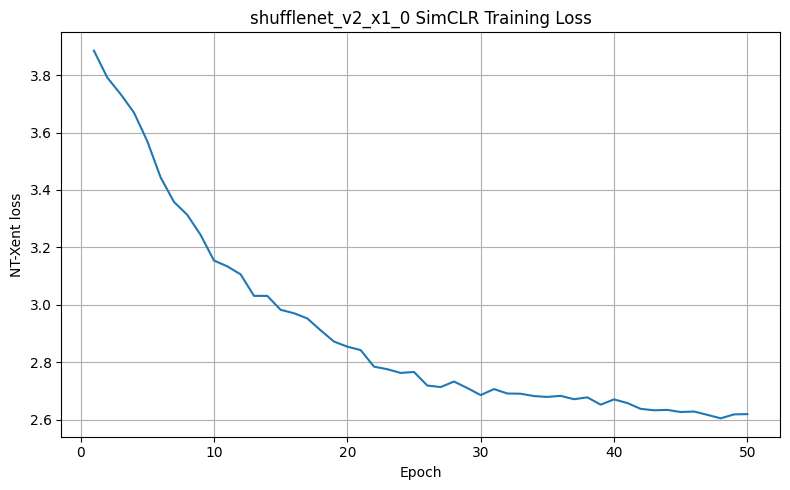

Saved: /content/drive/MyDrive/METALYX/shufflenet_experiment/results/shufflenet_v2_x1_0_simclr_loss.png


In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(loss_history) + 1), loss_history)
plt.xlabel("Epoch")
plt.ylabel("NT-Xent loss")
plt.title(f"{ENCODER_NAME} SimCLR Training Loss")
plt.grid(True)
plt.tight_layout()
loss_plot_path = os.path.join(RESULTS_DIR, f"{ENCODER_NAME}_simclr_loss.png")
plt.savefig(loss_plot_path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", loss_plot_path)

## 12. Extract features for train, validation, and test sets

In [ ]:
def extract_features(model, paths, transform, device, batch_size=64):
    class ImagePathDataset(Dataset):
        def __init__(self, paths, transform):
            self.paths = list(paths)
            self.transform = transform
        def __len__(self):
            return len(self.paths)
        def __getitem__(self, idx):
            path = self.paths[idx]
            image = cv2.imread(path)
            if image is None:
                raise RuntimeError(f"Could not read image: {path}")
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            return self.transform(image)

    loader = DataLoader(
        ImagePathDataset(paths, transform),
        batch_size=batch_size,
        shuffle=False,
        num_workers=2 if os.name != "nt" else 0,
        pin_memory=torch.cuda.is_available()
    )

    model.eval()
    all_features = []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device, non_blocking=True)
            features, _ = model(batch)
            all_features.append(features.cpu().numpy())

    return np.concatenate(all_features, axis=0).astype(np.float32)

X_train = extract_features(model, train_paths, feature_transform, device)
X_val = extract_features(model, val_paths, feature_transform, device)
X_test = extract_features(model, test_paths, feature_transform, device)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)
print("NaN in train features:", np.isnan(X_train).any())
print("Inf in train features:", np.isinf(X_train).any())
assert X_train.shape[1] == model.feature_dim
assert not (np.isnan(X_train).any() or np.isinf(X_train).any())

X_train: (1008, 1024)
X_val: (216, 1024)
X_test: (216, 1024)
NaN in train features: False
Inf in train features: False


## 13. Train the downstream Logistic Regression classifier

In [ ]:
classifier = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000, random_state=SEED))
])

classifier.fit(X_train, y_train)
print("Logistic Regression trained.")

Logistic Regression trained.


## 14. Evaluate on validation data

In [ ]:
y_val_pred = classifier.predict(X_val)
val_accuracy = accuracy_score(y_val, y_val_pred)
val_precision = precision_score(y_val, y_val_pred, average="weighted", zero_division=0)
val_recall = recall_score(y_val, y_val_pred, average="weighted", zero_division=0)
val_f1 = f1_score(y_val, y_val_pred, average="weighted", zero_division=0)

print(f"Validation accuracy : {val_accuracy * 100:.2f}%")
print(f"Validation precision: {val_precision * 100:.2f}%")
print(f"Validation recall   : {val_recall * 100:.2f}%")
print(f"Validation F1-score : {val_f1 * 100:.2f}%")

Validation accuracy : 94.91%
Validation precision: 95.04%
Validation recall   : 94.91%
Validation F1-score : 94.91%


## 15. Final evaluation on the held-out test set

Use validation results for model choices. Run this final test evaluation after the experiment settings are fixed.

In [ ]:
y_test_pred = classifier.predict(X_test)

test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred, average="weighted", zero_division=0)
test_recall = recall_score(y_test, y_test_pred, average="weighted", zero_division=0)
test_f1 = f1_score(y_test, y_test_pred, average="weighted", zero_division=0)

print(f"Test accuracy : {test_accuracy * 100:.2f}%")
print(f"Test precision: {test_precision * 100:.2f}%")
print(f"Test recall   : {test_recall * 100:.2f}%")
print(f"Test F1-score : {test_f1 * 100:.2f}%")

print("\nClassification report:")
print(classification_report(
    y_test, y_test_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))

Test accuracy : 96.76%
Test precision: 96.81%
Test recall   : 96.76%
Test F1-score : 96.76%

Classification report:
                 precision    recall  f1-score   support

        crazing     0.9730    1.0000    0.9863        36
      inclusion     0.9412    0.8889    0.9143        36
        patches     1.0000    1.0000    1.0000        36
 pitted_surface     0.8947    0.9444    0.9189        36
rolled-in_scale     1.0000    0.9722    0.9859        36
      scratches     1.0000    1.0000    1.0000        36

       accuracy                         0.9676       216
      macro avg     0.9681    0.9676    0.9676       216
   weighted avg     0.9681    0.9676    0.9676       216



## 16. Confusion matrix

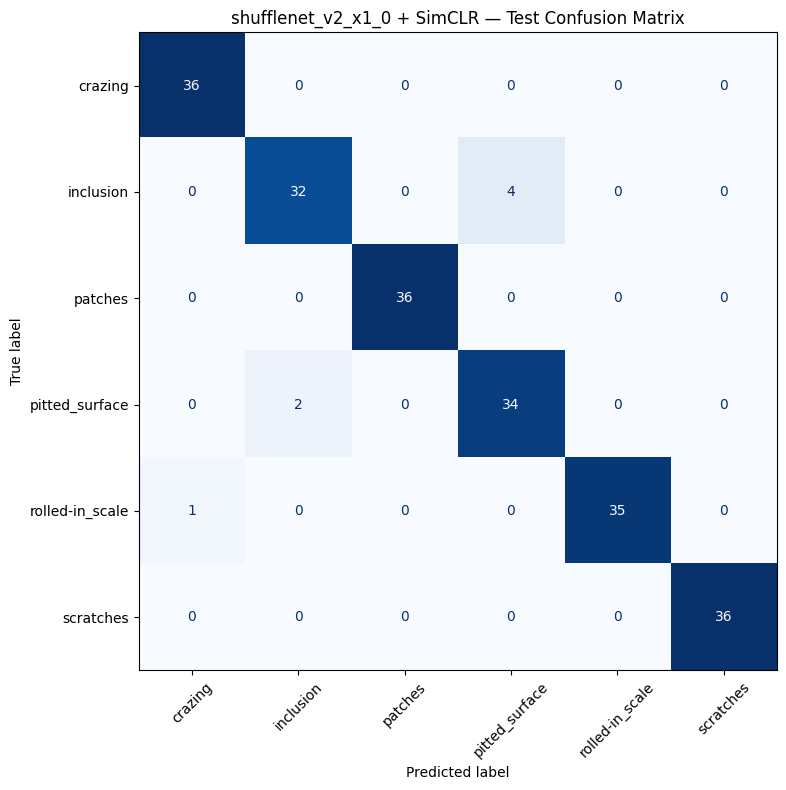

Saved: /content/drive/MyDrive/METALYX/shufflenet_experiment/results/shufflenet_v2_x1_0_simclr_confusion_matrix.png


In [ ]:
cm = confusion_matrix(y_test, y_test_pred, labels=list(range(len(class_names))))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(9, 8))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title(f"{ENCODER_NAME} + SimCLR — Test Confusion Matrix")
plt.tight_layout()
cm_path = os.path.join(RESULTS_DIR, f"{ENCODER_NAME}_simclr_confusion_matrix.png")
plt.savefig(cm_path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", cm_path)

## 17. Save features and metrics

In [ ]:
np.savez_compressed(
    os.path.join(RESULTS_DIR, f"{ENCODER_NAME}_simclr_features.npz"),
    X_train=X_train, y_train=y_train,
    X_val=X_val, y_val=y_val,
    X_test=X_test, y_test=y_test,
    train_paths=train_paths,
    val_paths=val_paths,
    test_paths=test_paths
)

metrics = {
    "encoder": ENCODER_NAME,
    "method": "SimCLR + Logistic Regression",
    "seed": SEED,
    "pretraining_images": int(len(train_paths)),
    "feature_dim": int(X_train.shape[1]),
    "epochs": NUM_EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "temperature": TEMPERATURE,
    "training_minutes": round(training_seconds / 60, 2),
    "validation_accuracy": float(val_accuracy),
    "validation_precision_weighted": float(val_precision),
    "validation_recall_weighted": float(val_recall),
    "validation_f1_weighted": float(val_f1),
    "test_accuracy": float(test_accuracy),
    "test_precision_weighted": float(test_precision),
    "test_recall_weighted": float(test_recall),
    "test_f1_weighted": float(test_f1)
}

metrics_path = os.path.join(RESULTS_DIR, f"{ENCODER_NAME}_simclr_metrics.json")
with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=2)

pd.DataFrame([metrics]).to_csv(
    os.path.join(RESULTS_DIR, f"{ENCODER_NAME}_simclr_metrics.csv"),
    index=False
)
print("Saved metrics:", metrics_path)
pd.DataFrame([metrics])

Saved metrics: /content/drive/MyDrive/METALYX/shufflenet_experiment/results/shufflenet_v2_x1_0_simclr_metrics.json


,encoder,method,seed,pretraining_images,feature_dim,epochs,batch_size,learning_rate,temperature,training_minutes,validation_accuracy,validation_precision_weighted,validation_recall_weighted,validation_f1_weighted,test_accuracy,test_precision_weighted,test_recall_weighted,test_f1_weighted
0,shufflenet_v2_x1_0,SimCLR + Logistic Regression,42,1008,1024,50,32,0.001,0.5,48.0,0.949074,0.950378,0.949074,0.949109,0.967593,0.968148,0.967593,0.96757


## 18. How to compare against ResNet18 correctly

1. Keep the split manifest created in Section 4 unchanged.
2. Change `ENCODER_NAME` in Section 2 to `resnet18`, then restart and run all cells again. Keep the same seed, augmentations, batch size, epochs, learning rate, temperature, feature transform, and Logistic Regression settings.
3. The output filenames are based on `ENCODER_NAME`, so the ResNet18 results are saved separately.
4. Compare the two encoders on the same split. Do not compare a ShuffleNet test score with a ResNet18 validation score.
5. Only after comparing the encoder results should you add B-spline features to ShuffleNet, if required.

**Important limitation:** The earlier downstream notebook extracts features for all 1,440 images after SimCLR training on all 1,440 images, then splits those features. That means the held-out classifier test images have already been seen during self-supervised encoder training. The 96.76% test result in that notebook is therefore not a strict unseen-image test. This new notebook avoids that issue by splitting first and pretraining only on the training partition.

In [ ]:
import os

base = "/content/drive/MyDrive/METALYX"

for root, dirs, files in os.walk(base):
    for f in files:
        if f.endswith((".pth", ".pt")):
            print(os.path.join(root, f))


/content/drive/MyDrive/METALYX/models/simclr_resnet18.pth
/content/drive/MyDrive/METALYX/shufflenet_experiment/models/simclr_shufflenet_v2_x1_0.pth
/content/drive/MyDrive/METALYX/shufflenet_experiment/models/simclr_shufflenet_v2_x1_0_latest.pth


## 11. Save the trained checkpoint

In [ ]:
checkpoint_path = os.path.join(MODEL_DIR, f"simclr_{ENCODER_NAME}.pth")
torch.save({
    "encoder_name": ENCODER_NAME,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "loss_history": loss_history,
    "projection_dim": PROJECTION_DIM,
    "temperature": TEMPERATURE,
    "num_epochs": NUM_EPOCHS,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "seed": SEED,
    "feature_dim": model.feature_dim,
    "training_seconds": training_seconds
}, checkpoint_path)
print("Saved checkpoint:", checkpoint_path)

Saved checkpoint: /content/drive/MyDrive/METALYX/shufflenet_experiment/models/simclr_shufflenet_v2_x1_0.pth
